## 0. Setup
Run this cell first. It imports the libraries and sets the plot style. (Colab already has all of them installed.)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Circle
from scipy.spatial.distance import cdist
from scipy.stats import norm
from sklearn.datasets import make_blobs, make_moons, load_digits
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.decomposition import PCA
import sklearn

plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["axes.grid"] = True
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


---
## 1. k-means on simple blobs
We make 400 points in 4 round groups and cluster them with k-means.

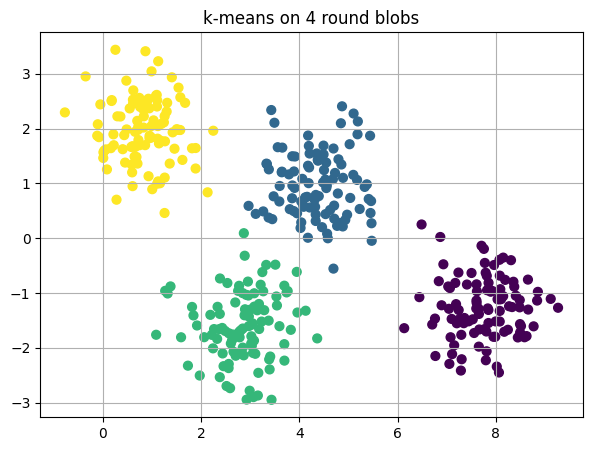

In [ ]:
X, y_true = make_blobs(n_samples=400, centers=4, cluster_std=0.60, random_state=0)
X = X[:, ::-1]                       # flip the axes for nicer plotting

kmeans = KMeans(n_clusters=4, random_state=0, n_init=10)
labels = kmeans.fit(X).predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap="viridis")
plt.title("k-means on 4 round blobs")
plt.show()

## 2. k-means draws a hard circle around each centre
This helper draws each cluster as a circle whose radius reaches its farthest point. Inside the circle = member, outside = not. There is **no probability**.

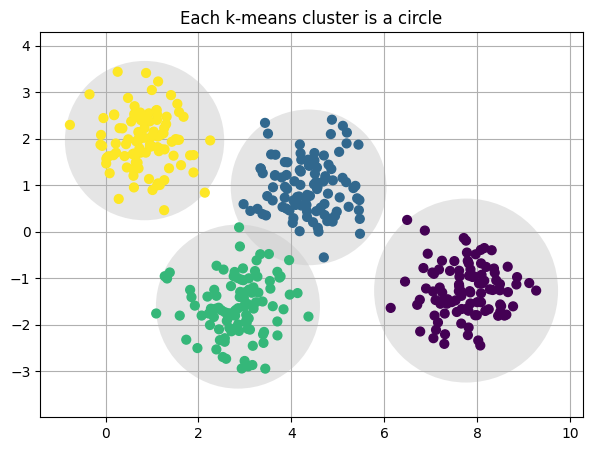

In [ ]:
def plot_kmeans(kmeans, X, n_clusters=4, rseed=0, ax=None):
    labels = kmeans.fit_predict(X)
    ax = ax or plt.gca()
    ax.axis("equal")
    ax.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap="viridis", zorder=2)
    centers = kmeans.cluster_centers_
    radii = [cdist(X[labels == i], [center]).max() for i, center in enumerate(centers)]
    for c, r in zip(centers, radii):
        ax.add_patch(Circle(c, r, fc="#CCCCCC", lw=3, alpha=0.5, zorder=1))

plot_kmeans(KMeans(n_clusters=4, random_state=0, n_init=10), X)
plt.title("Each k-means cluster is a circle")
plt.show()

## 3. Stretch the data: k-means gets muddled
Multiplying the data by a random 2×2 matrix turns each round blob into a long, tilted ellipse. k-means can still only draw circles.

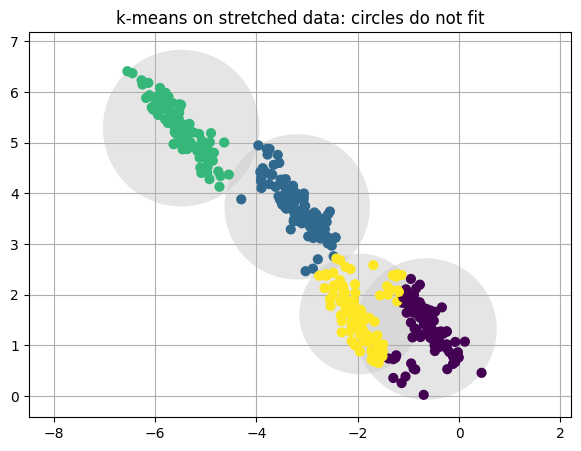

In [ ]:
rng = np.random.RandomState(13)
X_stretched = np.dot(X, rng.randn(2, 2))

plot_kmeans(KMeans(n_clusters=4, random_state=0, n_init=10), X_stretched)
plt.title("k-means on stretched data: circles do not fit")
plt.show()

---
## 4. The covariance matrix sets a cluster's shape
We make correlated 2-D points, compute their covariance matrix Σ, and draw its **eigenvectors** (the axes of the ellipse). The **eigenvalues** are the variance along each axis.

Covariance matrix:
 [[1.81 1.15]
 [1.15 1.58]]
Eigenvalues (variance along each axis): [2.85 0.54]


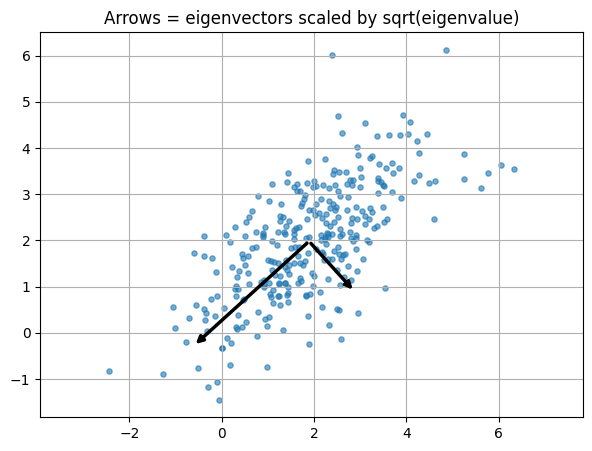

In [ ]:
r = np.random.RandomState(1)
true_cov = np.array([[2.0, 1.2], [1.2, 1.5]])
P = r.multivariate_normal([2, 2], true_cov, 300)

cov = np.cov(P.T)
eigvals, eigvecs = np.linalg.eigh(cov)
print("Covariance matrix:\n", cov.round(2))
print("Eigenvalues (variance along each axis):", eigvals[::-1].round(2))

plt.scatter(P[:, 0], P[:, 1], s=14, alpha=0.6)
center = P.mean(axis=0)
for val, vec in zip(eigvals, eigvecs.T):
    plt.annotate("", xy=center + 2 * np.sqrt(val) * vec, xytext=center,
                 arrowprops=dict(arrowstyle="-|>", lw=2.5, color="black"))
plt.axis("equal"); plt.title("Arrows = eigenvectors scaled by sqrt(eigenvalue)")
plt.show()

✏️ **Try it:** change `true_cov` to `[[2.0, 0], [0, 2.0]]`. What happens to the eigenvalues and the arrows? (This is the circle that k-means assumes.)

---
## 5. A Gaussian Mixture Model clusters like k-means
`GaussianMixture` has the same `fit` / `predict` interface as k-means.

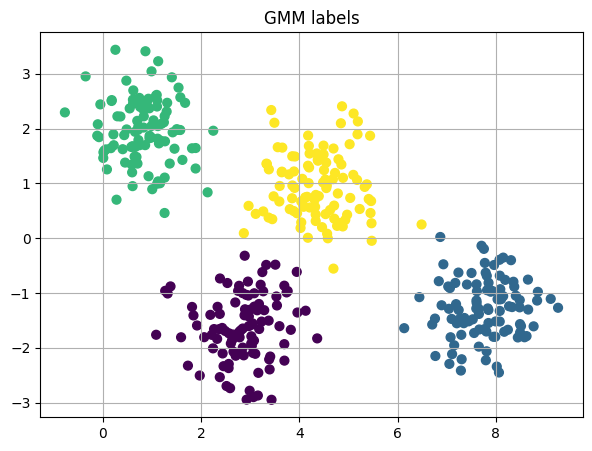

weights_ (pi_k): [0.247 0.249 0.25  0.255]
means_ shape: (4, 2)   covariances_ shape: (4, 2, 2)
converged_: True


In [ ]:
gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(X)
labels = gmm.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap="viridis")
plt.title("GMM labels")
plt.show()

print("weights_ (pi_k):", gmm.weights_.round(3))
print("means_ shape:", gmm.means_.shape, "  covariances_ shape:", gmm.covariances_.shape)
print("converged_:", gmm.converged_)

## 6. Soft clustering with `predict_proba`
Each row gives the probability that a point belongs to each cluster. Rows add up to 1.

[[0.    0.463 0.    0.537]
 [1.    0.    0.    0.   ]
 [1.    0.    0.    0.   ]
 [0.    0.    0.    1.   ]
 [1.    0.    0.    0.   ]]
Each row sums to 1: True


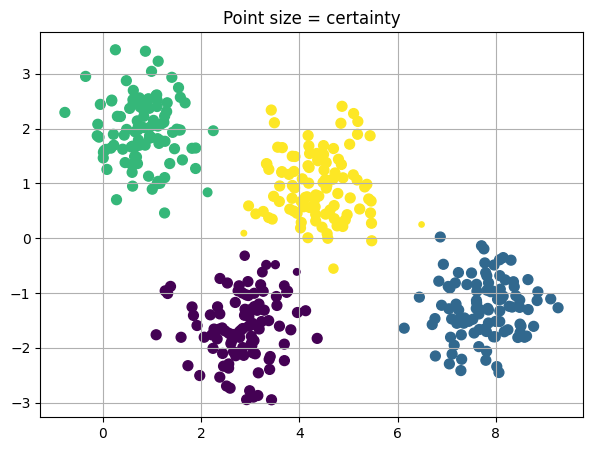

In [ ]:
probs = gmm.predict_proba(X)
print(probs[:5].round(3))
print("Each row sums to 1:", np.allclose(probs.sum(axis=1), 1))

# Point size shows how certain the model is; uncertain points are small
size = 50 * probs.max(axis=1) ** 2
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=size)
plt.title("Point size = certainty")
plt.show()

In [ ]:
# Which points is the model least sure about?
uncertain = np.argsort(probs.max(axis=1))[:5]
for i in uncertain:
    print(f"point {i:3d}  at {X[i].round(2)}   probabilities {probs[i].round(2)}")

point   0  at [6.49 0.25]   probabilities [0.   0.46 0.   0.54]
point 398  at [2.87 0.09]   probabilities [0.44 0.   0.   0.56]
point 385  at [ 3.95 -0.61]   probabilities [0.66 0.   0.   0.34]
point 224  at [ 3.51 -0.48]   probabilities [0.8 0.  0.  0.2]
point 120  at [2.14 0.84]   probabilities [0.01 0.   0.87 0.12]


## 7. Drawing the fitted Gaussians as ellipses
These helpers draw 1, 2 and 3 standard-deviation ellipses for each component.

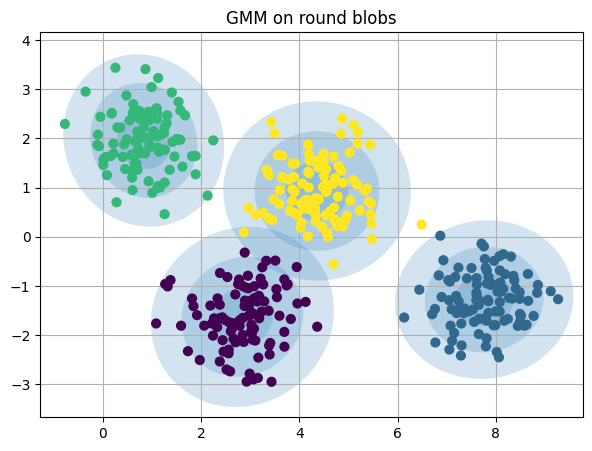

In [ ]:
def draw_ellipse(position, covariance, ax=None, **kwargs):
    ax = ax or plt.gca()
    if covariance.shape == (2, 2):                       # full covariance
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else:                                                # diag or spherical
        angle = 0
        width, height = 2 * np.sqrt(covariance) * np.ones(2)
    for nsig in range(1, 4):
        ax.add_patch(Ellipse(position, nsig * width, nsig * height, angle=angle, **kwargs))

def plot_gmm(gmm, X, label=True, ax=None):
    ax = ax or plt.gca()
    labels = gmm.fit(X).predict(X)
    if label:
        ax.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap="viridis", zorder=2)
    else:
        ax.scatter(X[:, 0], X[:, 1], s=40, zorder=2)
    ax.axis("equal")
    w_factor = 0.2 / gmm.weights_.max()
    for pos, covar, w in zip(gmm.means_, gmm.covariances_, gmm.weights_):
        draw_ellipse(pos, covar, ax=ax, alpha=w * w_factor)

plot_gmm(GaussianMixture(n_components=4, random_state=42), X)
plt.title("GMM on round blobs")
plt.show()

### The stretched data: k-means vs GMM side by side

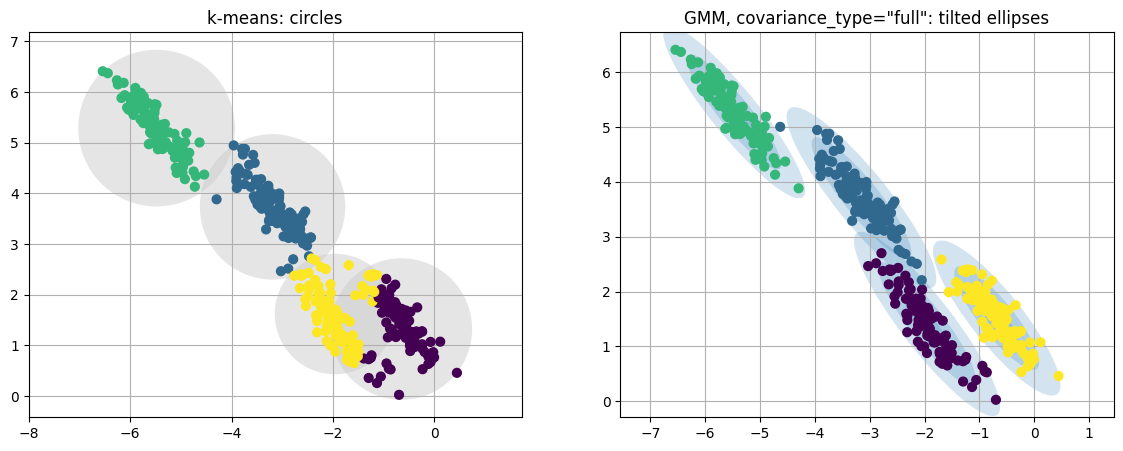

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_kmeans(KMeans(n_clusters=4, random_state=0, n_init=10), X_stretched, ax=axes[0])
axes[0].set_title("k-means: circles")
plot_gmm(GaussianMixture(n_components=4, covariance_type="full", random_state=42), X_stretched, ax=axes[1])
axes[1].set_title('GMM, covariance_type="full": tilted ellipses')
plt.show()

---
## 8. The EM algorithm, step by step

**E-step** (responsibilities): γₙₖ = πₖ·𝒩(xₙ | μₖ, Σₖ) / Σⱼ πⱼ·𝒩(xₙ | μⱼ, Σⱼ)

**M-step** (refit with weights): Nₖ = Σₙ γₙₖ, πₖ = Nₖ / N, μₖ = (1/Nₖ) Σₙ γₙₖ xₙ, σ²ₖ = (1/Nₖ) Σₙ γₙₖ (xₙ − μₖ)²

### 8a. One E-step by hand (the worked example from the slides)
Cluster A: μ = 0, σ = 1, π = 0.5. Cluster B: μ = 4, σ = 1, π = 0.5.

In [ ]:
for x in [1.0, 2.0, 3.0]:
    a = 0.5 * norm.pdf(x, loc=0, scale=1)     # pi_A * N(x | A)
    b = 0.5 * norm.pdf(x, loc=4, scale=1)     # pi_B * N(x | B)
    gamma_A = a / (a + b)
    print(f"x = {x}:  pi*N(x|A) = {a:.4f}   pi*N(x|B) = {b:.4f}   gamma(A) = {gamma_A:.2f}")

x = 1.0:  pi*N(x|A) = 0.1210   pi*N(x|B) = 0.0022   gamma(A) = 0.98
x = 2.0:  pi*N(x|A) = 0.0270   pi*N(x|B) = 0.0270   gamma(A) = 0.50
x = 3.0:  pi*N(x|A) = 0.0022   pi*N(x|B) = 0.1210   gamma(A) = 0.02


✏️ **Try it:** change the weight of A to 0.8 (and B to 0.2). How does γ(A) for x = 2 change?

### 8b. A complete EM loop in NumPy (1-D, 2 components)
We write EM ourselves, then compare with scikit-learn.

Our EM      -> weights [0.6 0.4]  means [-0.07  5.  ]  std [0.99 1.43]
scikit-learn -> weights [0.6 0.4]  means [-0.06  5.01]  std [1.   1.41]


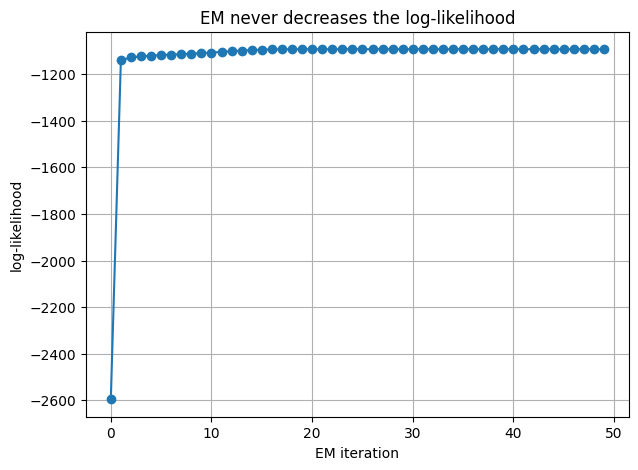

In [ ]:
rng = np.random.default_rng(0)
data = np.concatenate([rng.normal(0, 1, 300), rng.normal(5, 1.5, 200)])   # true: means 0 and 5

# Step 0: starting guesses
pi = np.array([0.5, 0.5])
mu = np.array([-1.0, 1.0])
var = np.array([1.0, 1.0])

log_likelihoods = []
for it in range(50):
    # E-step: responsibilities, shape (N, 2)
    dens = np.stack([pi[k] * norm.pdf(data, mu[k], np.sqrt(var[k])) for k in range(2)], axis=1)
    gamma = dens / dens.sum(axis=1, keepdims=True)
    log_likelihoods.append(np.log(dens.sum(axis=1)).sum())

    # M-step: weighted refit
    Nk = gamma.sum(axis=0)
    pi = Nk / len(data)
    mu = (gamma * data[:, None]).sum(axis=0) / Nk
    var = (gamma * (data[:, None] - mu) ** 2).sum(axis=0) / Nk

print("Our EM      -> weights", pi.round(2), " means", mu.round(2), " std", np.sqrt(var).round(2))
sk = GaussianMixture(2, random_state=0).fit(data.reshape(-1, 1))
order = np.argsort(sk.means_.ravel())
print("scikit-learn -> weights", sk.weights_[order].round(2), " means", sk.means_.ravel()[order].round(2),
      " std", np.sqrt(sk.covariances_.ravel()[order]).round(2))

plt.plot(log_likelihoods, marker="o")
plt.xlabel("EM iteration"); plt.ylabel("log-likelihood")
plt.title("EM never decreases the log-likelihood")
plt.show()

---
## 9. Covariance types: spherical, diag, full
The same tilted cluster, fitted three ways. **The scikit-learn default is `"full"`.**

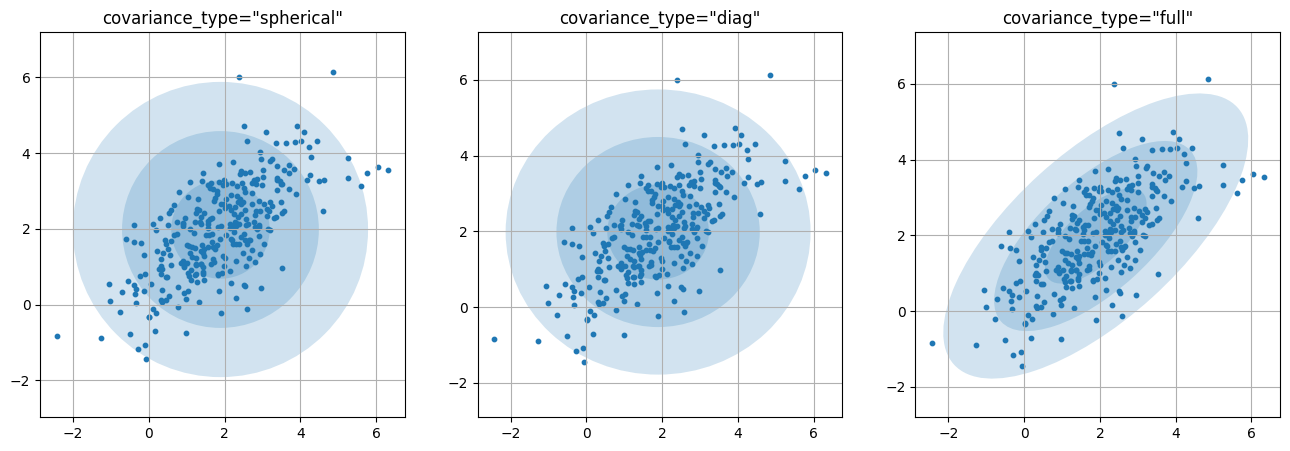

Numbers per covariance in 64 dimensions:  spherical 1 | diag 64 | full 2080


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, ct in zip(axes, ["spherical", "diag", "full"]):
    g = GaussianMixture(n_components=1, covariance_type=ct, random_state=0).fit(P)
    ax.scatter(P[:, 0], P[:, 1], s=10)
    draw_ellipse(g.means_[0], g.covariances_[0], ax=ax, alpha=0.2)
    ax.set_title(f'covariance_type="{ct}"'); ax.axis("equal")
plt.show()

d = 64
print("Numbers per covariance in", d, "dimensions:  spherical 1 | diag", d, "| full", d * (d + 1) // 2)

---
## 10. GMM as a density estimator
On two half-moons, 2 components make poor clusters, but 16 components together trace the shape.

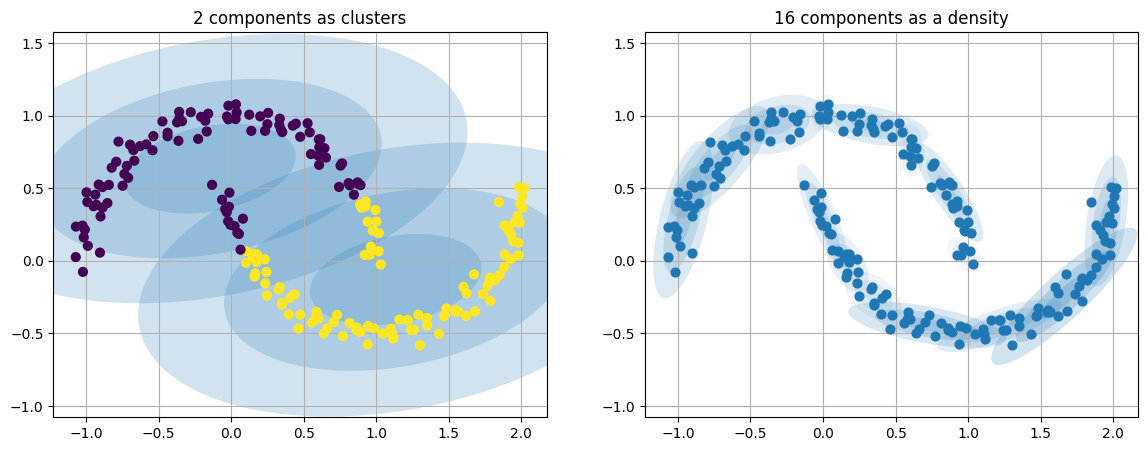

In [ ]:
Xmoon, ymoon = make_moons(200, noise=0.05, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_gmm(GaussianMixture(n_components=2, covariance_type="full", random_state=0), Xmoon, ax=axes[0])
axes[0].set_title("2 components as clusters")
gmm16 = GaussianMixture(n_components=16, covariance_type="full", random_state=0)
plot_gmm(gmm16, Xmoon, label=False, ax=axes[1])
axes[1].set_title("16 components as a density")
plt.show()

## 11. Generate new data with `sample()`

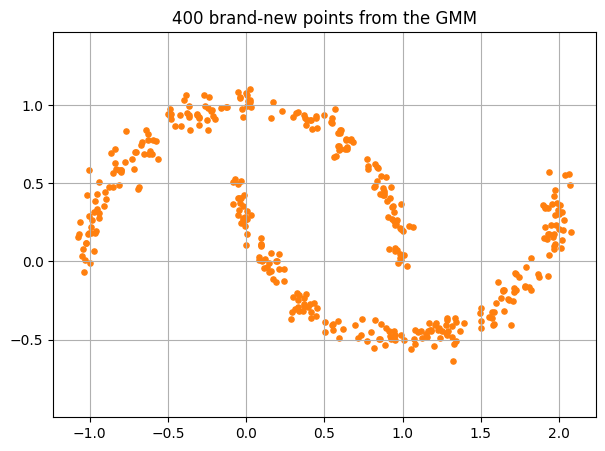

How many new points each of the 16 components produced: [20 33 30 33 39 11 27 33 30 14 19 37 18 19  7 30]


In [ ]:
Xnew, ynew = gmm16.sample(400)
plt.scatter(Xnew[:, 0], Xnew[:, 1], s=14, c="tab:orange")
plt.axis("equal"); plt.title("400 brand-new points from the GMM")
plt.show()
print("How many new points each of the 16 components produced:", np.bincount(ynew, minlength=16))

In [ ]:
# A density model can also SCORE points: low log-density = unusual (anomaly detection)
test_points = np.array([[0.0, 1.0], [1.0, 0.0], [3.0, 3.0]])
print("log-density:", gmm16.score_samples(test_points).round(2))
print("The point (3, 3) is far from both moons, so it gets a much lower score.")

log-density: [   1.24    0.35 -268.37]
The point (3, 3) is far from both moons, so it gets a much lower score.


## 12. How many components? AIC and BIC (slide 18)
AIC = 2p − 2 ln L, BIC = p ln n − 2 ln L. **Lower is better.**

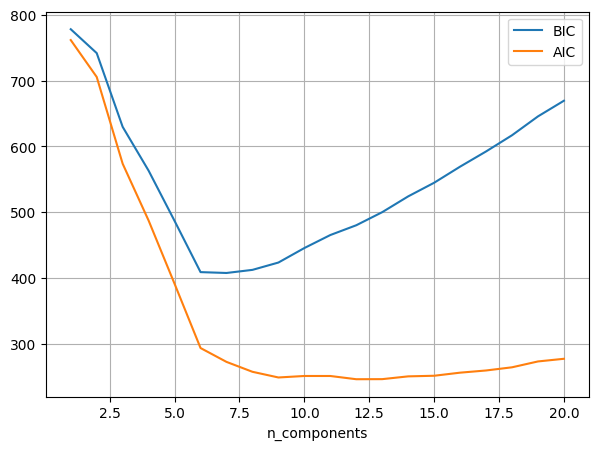

Lowest BIC at 7 components; lowest AIC at 12


In [ ]:
n_components = np.arange(1, 21)
models = [GaussianMixture(n, covariance_type="full", random_state=0).fit(Xmoon) for n in n_components]
bic = [m.bic(Xmoon) for m in models]
aic = [m.aic(Xmoon) for m in models]

plt.plot(n_components, bic, label="BIC")
plt.plot(n_components, aic, label="AIC")
plt.legend(); plt.xlabel("n_components")
plt.show()
print("Lowest BIC at", n_components[np.argmin(bic)], "components; lowest AIC at", n_components[np.argmin(aic)])

---
## 13. Generating handwritten digits
Pipeline: 64-pixel digits → **PCA** (keep 99% of variance) → **GMM** → **sample** → **inverse PCA** → new digits.

digits.data shape: (1797, 64)


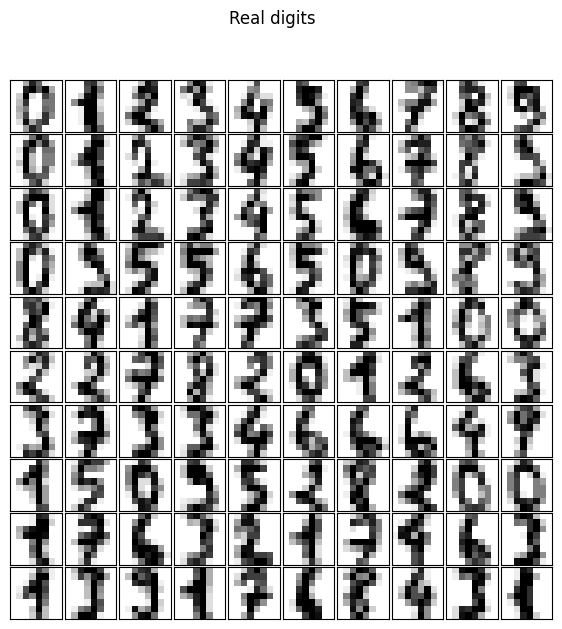

In [ ]:
digits = load_digits()
print("digits.data shape:", digits.data.shape)

def plot_digits(data, title):
    fig, ax = plt.subplots(10, 10, figsize=(7, 7), subplot_kw=dict(xticks=[], yticks=[]))
    fig.subplots_adjust(hspace=0.05, wspace=0.05)
    for i, axi in enumerate(ax.flat):
        axi.imshow(data[i].reshape(8, 8), cmap="binary")
        axi.set(xticks=[], yticks=[]); axi.grid(False)
    fig.suptitle(title)
    plt.show()

plot_digits(digits.data, "Real digits")

After PCA: (1797, 41) (64 -> 41 dimensions)


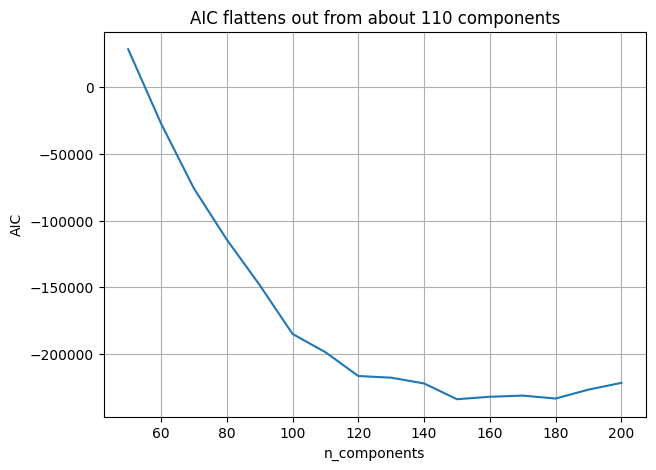

In [ ]:
pca = PCA(0.99, whiten=True)
data = pca.fit_transform(digits.data)
print("After PCA:", data.shape, "(64 -> %d dimensions)" % data.shape[1])

n_components = np.arange(50, 210, 10)
models = [GaussianMixture(n, covariance_type="full", random_state=0) for n in n_components]
aics = [model.fit(data).aic(data) for model in models]
plt.plot(n_components, aics); plt.xlabel("n_components"); plt.ylabel("AIC")
plt.title("AIC flattens out from about 110 components")
plt.show()

converged: True


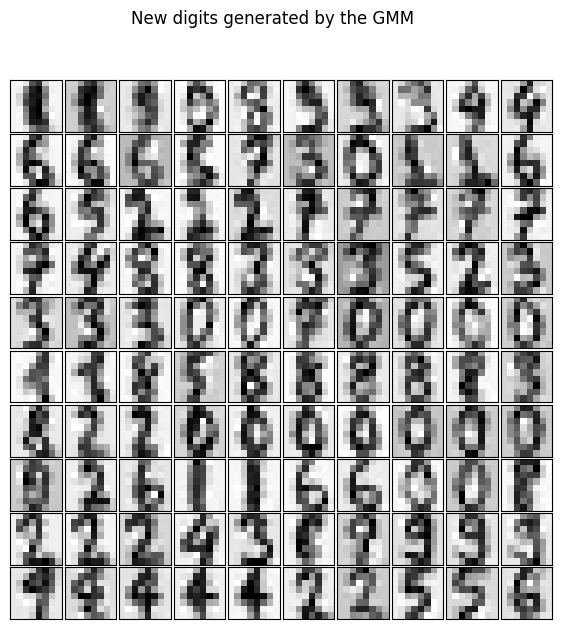

In [ ]:
gmm = GaussianMixture(110, covariance_type="full", random_state=0)
gmm.fit(data)
print("converged:", gmm.converged_)

data_new, _ = gmm.sample(100)
digits_new = pca.inverse_transform(data_new)
plot_digits(digits_new, "New digits generated by the GMM")

✏️ **Try it:** run the last cell again. You get a different set of new digits every time.

---
## 14. The Chinese restaurant process
Each new customer joins table k with probability ∝ nₖ (its size), or opens a new table with probability ∝ α. Let's simulate 1,000 customers.

Number of tables: 9 | sizes: [614, 309, 35, 33, 4, 2, 1, 1, 1]


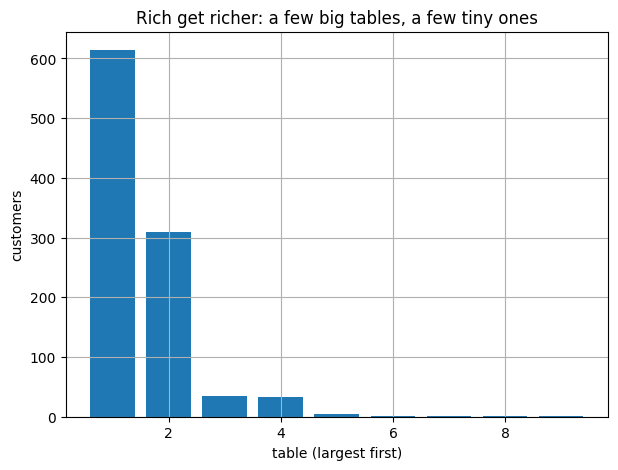

In [ ]:
def chinese_restaurant(n_customers=1000, alpha=2.0, seed=3):
    rng = np.random.default_rng(seed)
    tables = []
    for n in range(n_customers):
        p = np.array(tables + [alpha], dtype=float)
        p /= p.sum()
        k = rng.choice(len(p), p=p)
        if k == len(tables):
            tables.append(1)        # open a new table
        else:
            tables[k] += 1          # join an existing table
    return sorted(tables, reverse=True)

tables = chinese_restaurant(alpha=2.0)
print("Number of tables:", len(tables), "| sizes:", tables)
plt.bar(range(1, len(tables) + 1), tables)
plt.xlabel("table (largest first)"); plt.ylabel("customers")
plt.title("Rich get richer: a few big tables, a few tiny ones")
plt.show()

✏️ **Try it:** set `alpha=0.5` and then `alpha=10`. How does the number of tables change?

## 15. Bayesian GMM in action
Ask for 10 components and let the model switch off the ones it does not need.

weights: [0.25 0.   0.25 0.5  0.   0.   0.   0.   0.   0.  ]
Estimated number of clusters: 3


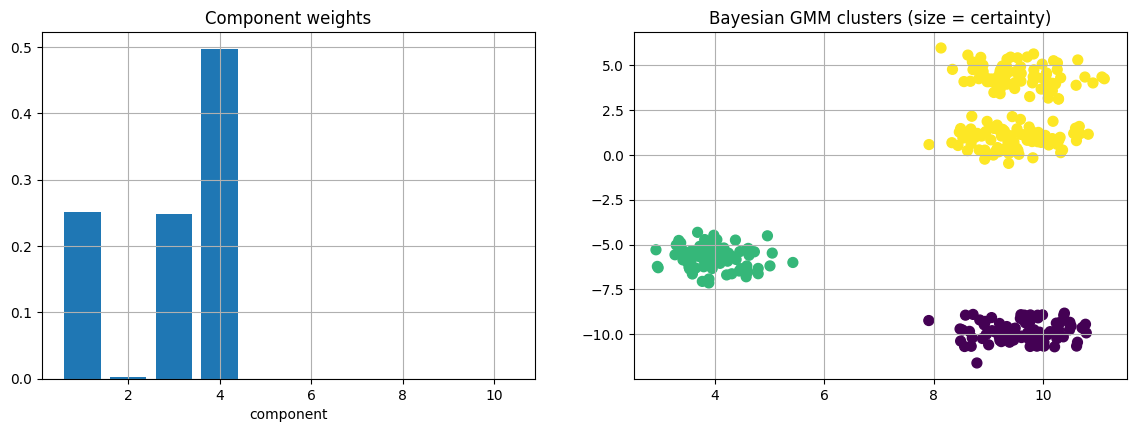

In [ ]:
X, y = make_blobs(n_samples=350, centers=4, cluster_std=0.6, random_state=4)

bay_gmm = BayesianGaussianMixture(n_components=10, n_init=10, random_state=0)
bay_gmm.fit(X)

weights = np.round(bay_gmm.weights_, 2)
print("weights:", weights)
print("Estimated number of clusters:", (weights > 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, 11), bay_gmm.weights_); axes[0].set_xlabel("component"); axes[0].set_title("Component weights")
probs = bay_gmm.predict_proba(X)
axes[1].scatter(X[:, 0], X[:, 1], c=bay_gmm.predict(X), cmap="viridis", s=50 * probs.max(axis=1) ** 2)
axes[1].set_title("Bayesian GMM clusters (size = certainty)")
plt.show()

**What to notice:** two of the four generated blobs (top right) are very close together, so the model often treats them as one cluster. With scikit-learn 1.9 it finds **3** clusters. A different version may give a slightly different answer.

✏️ **Try it:** change `cluster_std=0.6` to `0.3`, so the blobs are better separated. Does it now find 4?